# Atividade 2 — Regressão linear multivariada: preços de casas na Califórnia

**Disciplina:** RNA e Deep Learning — CESAR School 2026.01-A  
**Modelo:** regressão linear em PyTorch com 8 variáveis de entrada

Este notebook adapta a estrutura do notebook 2.6 para um problema multivariado. O objetivo é prever o valor mediano de casas em setores censitários da Califórnia usando o dataset *California Housing* do scikit-learn.


## 1. Bibliotecas e reprodutibilidade

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

import torch
from torch import nn, optim

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.style.use('seaborn-v0_8-whitegrid')


## 2. Dados e análise exploratória

In [2]:
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target

df = X.copy()
df['MedHouseVal'] = y

print(f'Quantidade de setores censitários: {df.shape[0]:,}')
print(f'Quantidade de variáveis de entrada: {X.shape[1]}')
df.head()


Quantidade de setores censitários: 20,640
Quantidade de variáveis de entrada: 8


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


### Significado das variáveis

Cada linha representa um grupo de quarteirões (*block group*) do censo da Califórnia.

| Variável | Significado |
|---|---|
| `MedInc` | renda mediana do grupo, em dezenas de milhares de dólares |
| `HouseAge` | idade mediana das casas, em anos |
| `AveRooms` | média de cômodos por domicílio |
| `AveBedrms` | média de quartos por domicílio |
| `Population` | população do grupo |
| `AveOccup` | média de moradores por domicílio |
| `Latitude` | latitude geográfica |
| `Longitude` | longitude geográfica |
| `MedHouseVal` | **alvo:** valor mediano das casas, em centenas de milhares de dólares |


### Estatísticas descritivas

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


### Dispersão de duas variáveis contra o preço

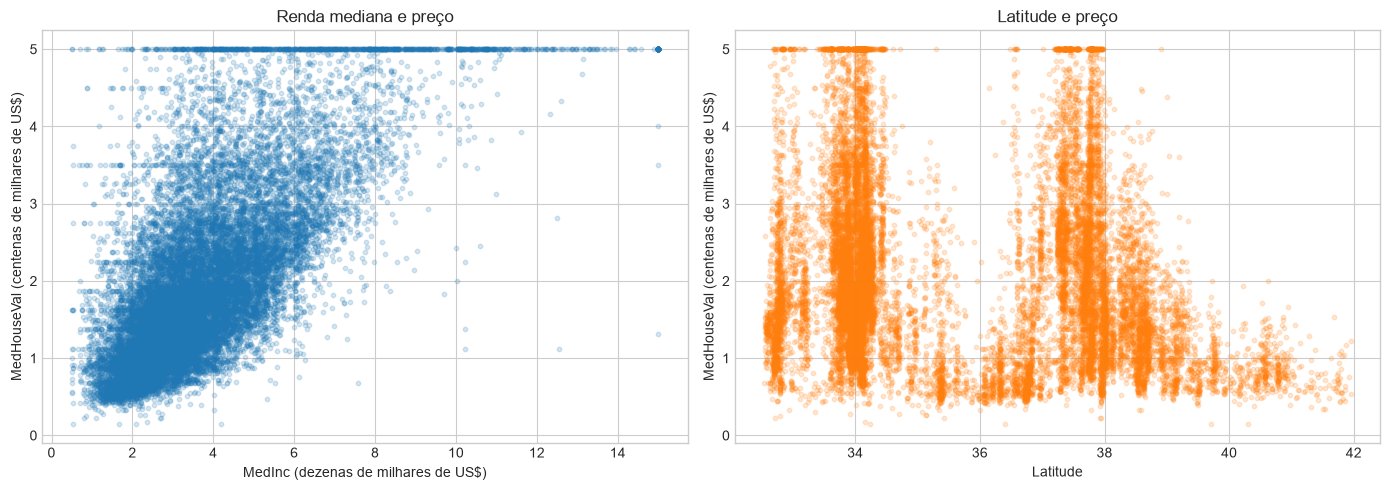

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df['MedInc'], df['MedHouseVal'], alpha=0.18, s=10, color='tab:blue')
axes[0].set(title='Renda mediana e preço', xlabel='MedInc (dezenas de milhares de US$)',
            ylabel='MedHouseVal (centenas de milhares de US$)')

axes[1].scatter(df['Latitude'], df['MedHouseVal'], alpha=0.18, s=10, color='tab:orange')
axes[1].set(title='Latitude e preço', xlabel='Latitude',
            ylabel='MedHouseVal (centenas de milhares de US$)')

plt.tight_layout()
plt.show()


A relação com a renda mediana é claramente positiva, embora não seja perfeitamente linear. A latitude também ajuda a explicar o preço, mas seu efeito parece depender de localização e de outras variáveis; por isso, ela é útil no modelo junto com longitude e os demais atributos.

## 3. Separação em treino, validação e teste

In [5]:
# Primeiro, separamos 70% para treino e 30% temporariamente.
X_train_raw, X_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)

# Os 30% restantes são divididos igualmente: 15% validação e 15% teste.
X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_temp_raw, y_temp_raw, test_size=0.50, random_state=SEED
)

print('Treino:    ', X_train_raw.shape, y_train_raw.shape)
print('Validação: ', X_val_raw.shape, y_val_raw.shape)
print('Teste:     ', X_test_raw.shape, y_test_raw.shape)


Treino:     (14448, 8) (14448,)
Validação:  (3096, 8) (3096,)
Teste:      (3096, 8) (3096,)


## 4. Padronização sem vazamento de dados

`StandardScaler` transforma cada coluna em aproximadamente média 0 e desvio padrão 1. Os dois scalers são ajustados **exclusivamente no treino**. Depois, seus parâmetros são apenas aplicados à validação e ao teste. Assim, nenhuma informação desses conjuntos influencia os parâmetros do pré-processamento.


In [6]:
x_scaler = StandardScaler().fit(X_train_raw)
y_scaler = StandardScaler().fit(y_train_raw.to_numpy().reshape(-1, 1))

X_train = torch.tensor(x_scaler.transform(X_train_raw), dtype=torch.float32)
X_val = torch.tensor(x_scaler.transform(X_val_raw), dtype=torch.float32)
X_test = torch.tensor(x_scaler.transform(X_test_raw), dtype=torch.float32)

y_train = torch.tensor(y_scaler.transform(y_train_raw.to_numpy().reshape(-1, 1)), dtype=torch.float32)
y_val = torch.tensor(y_scaler.transform(y_val_raw.to_numpy().reshape(-1, 1)), dtype=torch.float32)
y_test = torch.tensor(y_scaler.transform(y_test_raw.to_numpy().reshape(-1, 1)), dtype=torch.float32)

print('Formato dos tensores de treino:', X_train.shape, y_train.shape)
print('Média de X_train padronizado (aprox.):', X_train.mean(dim=0).numpy().round(3))
print('Média de y_train padronizado (aprox.):', round(y_train.mean().item(), 3))


Formato dos tensores de treino: torch.Size([14448, 8]) torch.Size([14448, 1])
Média de X_train padronizado (aprox.): [ 0. -0.  0. -0.  0.  0. -0.  0.]
Média de y_train padronizado (aprox.): 0.0


## 5. Modelo e treinamento

Como agora existem 8 atributos por exemplo, a camada linear recebe 8 entradas e produz uma saída:

$$\hat{y} = w_1x_1 + w_2x_2 + \dots + w_8x_8 + b$$

O treinamento usa MSE nos valores padronizados e `SGD` em lote completo, mantendo uma curva de custo separada para treino e validação.

In [7]:
torch.manual_seed(SEED)
model = nn.Linear(8, 1)
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.05)

print(model)
print('Pesos iniciais:', model.weight.detach().numpy().round(3))
print('Bias inicial:', round(model.bias.item(), 3))


Linear(in_features=8, out_features=1, bias=True)
Pesos iniciais: [[ 0.27   0.293 -0.083  0.325 -0.077  0.071 -0.172  0.208]]
Bias inicial: 0.312


In [8]:
def train_epoch(model, optimizer, criterion, features, targets):
    model.train()
    optimizer.zero_grad()
    predictions = model(features)
    loss = criterion(predictions, targets)
    loss.backward()
    optimizer.step()
    return loss.item()


def evaluate_loss(model, criterion, features, targets):
    model.eval()
    with torch.no_grad():
        return criterion(model(features), targets).item()


In [9]:
n_epochs = 800
train_losses, val_losses = [], []

for epoch in range(n_epochs):
    train_loss = train_epoch(model, optimizer, criterion, X_train, y_train)
    val_loss = evaluate_loss(model, criterion, X_val, y_val)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if (epoch + 1) % 100 == 0:
        print(f'Época {epoch + 1:>3}/{n_epochs}: MSE treino = {train_loss:.4f} | MSE validação = {val_loss:.4f}')


Época 100/800: MSE treino = 0.4110 | MSE validação = 0.4238
Época 200/800: MSE treino = 0.3962 | MSE validação = 0.4095
Época 300/800: MSE treino = 0.3923 | MSE validação = 0.4057
Época 400/800: MSE treino = 0.3912 | MSE validação = 0.4045


Época 500/800: MSE treino = 0.3909 | MSE validação = 0.4041
Época 600/800: MSE treino = 0.3907 | MSE validação = 0.4039


Época 700/800: MSE treino = 0.3907 | MSE validação = 0.4038
Época 800/800: MSE treino = 0.3907 | MSE validação = 0.4038


### Curvas de custo

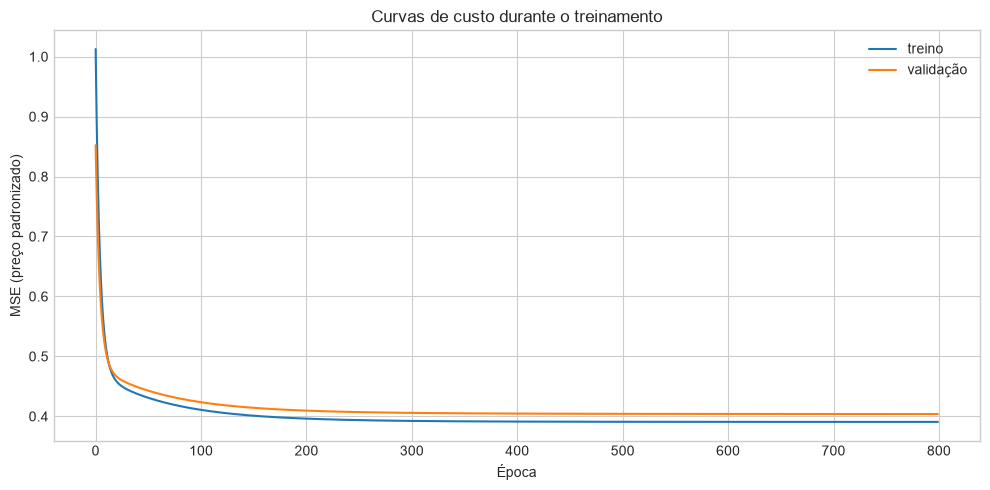

MSE final — treino: 0.3907 | validação: 0.4038


In [10]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='treino')
plt.plot(val_losses, label='validação')
plt.xlabel('Época')
plt.ylabel('MSE (preço padronizado)')
plt.title('Curvas de custo durante o treinamento')
plt.legend()
plt.tight_layout()
plt.show()

print(f'MSE final — treino: {train_losses[-1]:.4f} | validação: {val_losses[-1]:.4f}')


## 6. Avaliação final no teste: RMSE em dólares e baseline

In [11]:
model.eval()
with torch.no_grad():
    y_pred_test_scaled = model(X_test).numpy()

# Retornamos à unidade original do dataset e convertemos de centenas de milhares para dólares.
y_pred_test = y_scaler.inverse_transform(y_pred_test_scaled).ravel() * 100_000
y_test_dollars = y_test_raw.to_numpy() * 100_000

rmse_test = mean_squared_error(y_test_dollars, y_pred_test) ** 0.5

# Baseline: prever para qualquer casa a média de preço observada somente no treino.
baseline_prediction = y_train_raw.mean() * 100_000
y_baseline_test = np.full_like(y_test_dollars, baseline_prediction, dtype=float)
rmse_baseline = mean_squared_error(y_test_dollars, y_baseline_test) ** 0.5

improvement = 100 * (1 - rmse_test / rmse_baseline)

print(f'RMSE do modelo no teste:  US$ {rmse_test:,.2f}')
print(f'RMSE do baseline no teste: US$ {rmse_baseline:,.2f}')
print(f'Redução do RMSE contra o baseline: {improvement:.1f}%')
print(f'Preço médio do treino (baseline): US$ {baseline_prediction:,.2f}')


RMSE do modelo no teste:  US$ 72,163.16
RMSE do baseline no teste: US$ 114,992.22
Redução do RMSE contra o baseline: 37.2%
Preço médio do treino (baseline): US$ 206,923.96


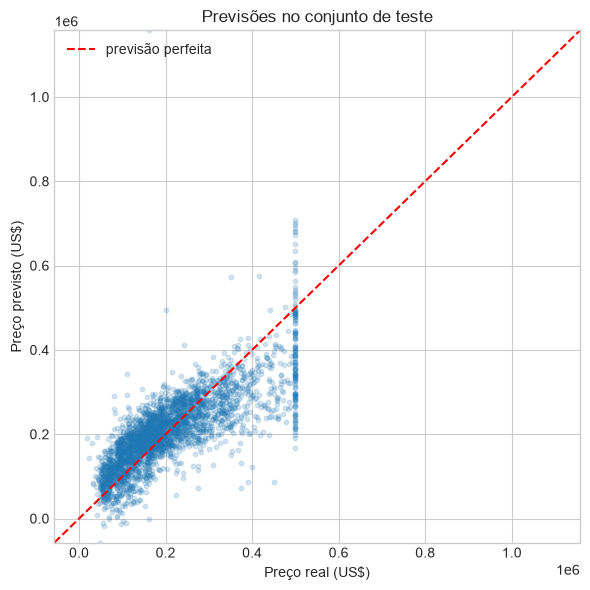

In [12]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test_dollars, y_pred_test, alpha=0.18, s=10)
limits = [min(y_test_dollars.min(), y_pred_test.min()), max(y_test_dollars.max(), y_pred_test.max())]
plt.plot(limits, limits, 'r--', label='previsão perfeita')
plt.xlim(limits)
plt.ylim(limits)
plt.xlabel('Preço real (US$)')
plt.ylabel('Preço previsto (US$)')
plt.title('Previsões no conjunto de teste')
plt.legend()
plt.tight_layout()
plt.show()


## 7. Interpretação dos pesos

In [13]:
weights = pd.Series(model.weight.detach().numpy().ravel(), index=X.columns, name='peso')
weights_sorted = weights.sort_values()

print('Pesos aprendidos (entradas padronizadas; saída padronizada):')
display(weights_sorted.to_frame().style.format({'peso': '{:+.4f}'}))

print()
print('Variáveis que mais diminuem o preço previsto (peso mais negativo):')
for variable, weight in weights_sorted.head(3).items():
    print(f'  {variable}: {weight:+.4f}')

print()
print('Variáveis que mais aumentam o preço previsto (peso mais positivo):')
for variable, weight in weights_sorted.tail(3).sort_values(ascending=False).items():
    print(f'  {variable}: {weight:+.4f}')


Pesos aprendidos (entradas padronizadas; saída padronizada):


,peso
Latitude,-0.7634
Longitude,-0.7420
AveRooms,-0.2650
AveOccup,-0.0362
Population,-0.0005
HouseAge,+0.1063
AveBedrms,+0.3060
MedInc,+0.7371



Variáveis que mais diminuem o preço previsto (peso mais negativo):
  Latitude: -0.7634
  Longitude: -0.7420
  AveRooms: -0.2650

Variáveis que mais aumentam o preço previsto (peso mais positivo):
  MedInc: +0.7371
  AveBedrms: +0.3060
  HouseAge: +0.1063


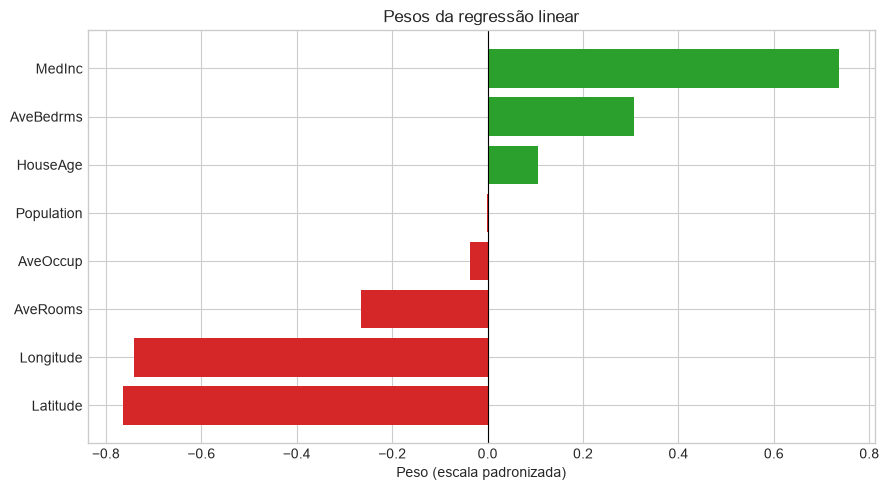

In [14]:
plt.figure(figsize=(9, 5))
colors = ['tab:red' if value < 0 else 'tab:green' for value in weights_sorted]
plt.barh(weights_sorted.index, weights_sorted.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Peso (escala padronizada)')
plt.title('Pesos da regressão linear')
plt.tight_layout()
plt.show()


Os pesos positivos indicam que, mantendo as demais variáveis constantes, aumentar a variável está associado a elevar a previsão; pesos negativos indicam o contrário. A comparação direta de suas magnitudes só faz sentido porque as **entradas foram padronizadas**: uma variação de uma unidade em cada entrada agora representa um desvio padrão da respectiva variável. Sem isso, um peso associado a latitude (medida em graus) e outro associado a população (medida em pessoas) estariam em unidades incompatíveis, e seu tamanho refletiria principalmente a escala numérica original.

Também é importante não interpretar os pesos como causalidade. Os atributos possuem correlações entre si — latitude e longitude, por exemplo, representam localização — e cada peso é um efeito condicional aos demais.


## 8. Conclusão

O modelo linear supera claramente o baseline da média quando avaliado por RMSE em dólares, portanto captura parte relevante da variação dos preços. Ainda assim, o gráfico de previsões mostra dispersão e o problema tem padrões geográficos e relações não lineares que uma única camada linear não consegue representar bem. Para melhorar, eu tentaria: (1) acrescentar termos não lineares e interações, especialmente de localização; (2) usar regularização Ridge/Lasso e validação cruzada para selecionar hiperparâmetros; e (3) comparar com modelos não lineares, como uma rede com camadas ocultas, Random Forest ou Gradient Boosting.
